image size: (300, 400, 3)
pixel value: [  0 200 255]


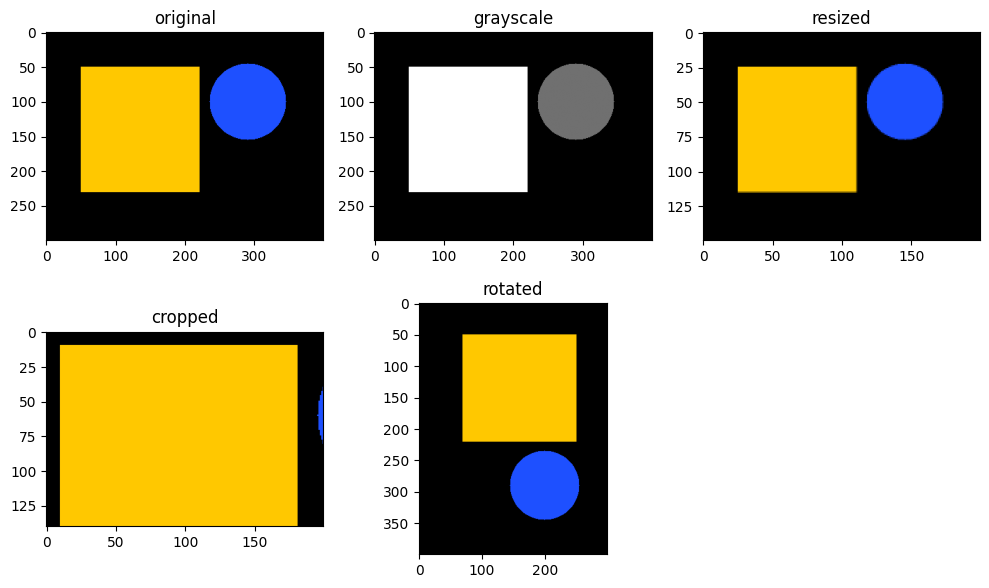

In [1]:
%pip install opencv-python numpy matplotlib
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = np.zeros((300, 400, 3), dtype=np.uint8)
cv2.rectangle(img, (50, 50), (220, 230), (0, 200, 255), -1)
cv2.circle(img, (290, 100), 55, (255, 80, 30), -1)

print("image size:", img.shape)
print("pixel value:", img[50, 50])

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
resize = cv2.resize(img, (200, 150))
crop = img[40:180, 40:240]
rotate = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)
cv2.imwrite("gray_image.jpg", gray)

plt.figure(figsize=(10, 6))
plt.subplot(2, 3, 1); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.title("original")
plt.subplot(2, 3, 2); plt.imshow(gray, cmap="gray"); plt.title("grayscale")
plt.subplot(2, 3, 3); plt.imshow(cv2.cvtColor(resize, cv2.COLOR_BGR2RGB)); plt.title("resized")
plt.subplot(2, 3, 4); plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)); plt.title("cropped")
plt.subplot(2, 3, 5); plt.imshow(cv2.cvtColor(rotate, cv2.COLOR_BGR2RGB)); plt.title("rotated")
plt.tight_layout()
plt.show()

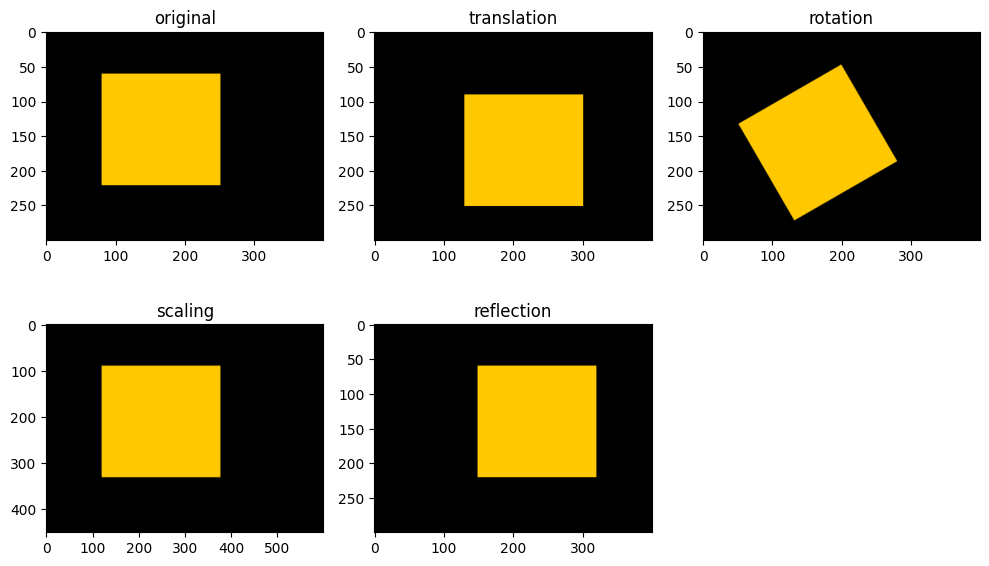

In [2]:

%pip install opencv-python numpy matplotlib
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = np.zeros((300, 400, 3), dtype=np.uint8)
cv2.rectangle(img, (80, 60), (250, 220), (0, 200, 255), -1)
h, w = img.shape[:2]

t = np.float32([[1, 0, 50], [0, 1, 30]])
translation = cv2.warpAffine(img, t, (w, h))

r = cv2.getRotationMatrix2D((w/2, h/2), 30, 1)
rotation = cv2.warpAffine(img, r, (w, h))

scaling = cv2.resize(img, None, fx=1.5, fy=1.5)
reflection = cv2.flip(img, 1)

plt.figure(figsize=(10, 6))
plt.subplot(2, 3, 1); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.title("original")
plt.subplot(2, 3, 2); plt.imshow(cv2.cvtColor(translation, cv2.COLOR_BGR2RGB)); plt.title("translation")
plt.subplot(2, 3, 3); plt.imshow(cv2.cvtColor(rotation, cv2.COLOR_BGR2RGB)); plt.title("rotation")
plt.subplot(2, 3, 4); plt.imshow(cv2.cvtColor(scaling, cv2.COLOR_BGR2RGB)); plt.title("scaling")
plt.subplot(2, 3, 5); plt.imshow(cv2.cvtColor(reflection, cv2.COLOR_BGR2RGB)); plt.title("reflection")
plt.tight_layout()
plt.show()


In [3]:

%pip install opencv-python numpy
import cv2
import numpy as np

source = np.float32([[50, 50], [350, 50], [350, 250], [50, 250]])
destination = np.float32([[80, 70], [320, 40], [370, 260], [30, 230]])

h, status = cv2.findHomography(source, destination, cv2.RANSAC)
print("homography matrix:")
print(h)

points = source.reshape(-1, 1, 2)
mapped_points = cv2.perspectiveTransform(points, h)
print("mapped points:")
print(mapped_points.reshape(-1, 2))


homography matrix:
[[ 4.95120445e-01 -2.61581223e-01  6.07628166e+01]
 [-1.19209389e-01  4.54478073e-01  4.66213712e+01]
 [-7.16491662e-04 -1.17356393e-03  1.00000000e+00]]
mapped points:
[[ 80.  70.]
 [320.  40.]
 [370. 260.]
 [ 30. 230.]]


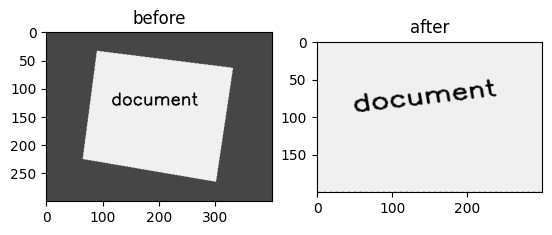

In [4]:

%pip install opencv-python numpy matplotlib
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = np.zeros((300, 400, 3), dtype=np.uint8) + 70
corners = np.array([[90, 35], [330, 65], [300, 265], [65, 225]], np.int32)
cv2.fillConvexPoly(img, corners, (240, 240, 240))
cv2.putText(img, "document", (115, 130), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 0), 2)

source = np.float32([[90, 35], [330, 65], [300, 265], [65, 225]])
destination = np.float32([[0, 0], [299, 0], [299, 199], [0, 199]])

matrix = cv2.getPerspectiveTransform(source, destination)
result = cv2.warpPerspective(img, matrix, (300, 200))

plt.subplot(1, 2, 1); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.title("before")
plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB)); plt.title("after")
plt.show()


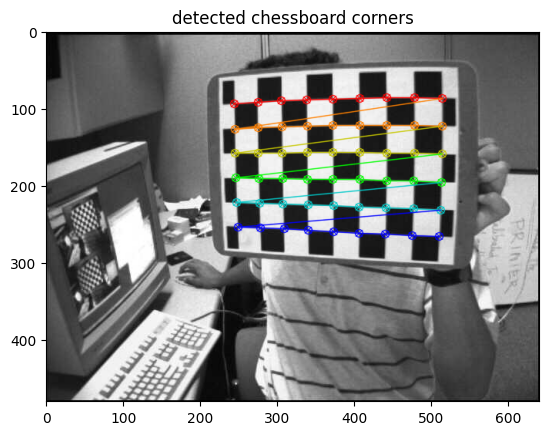

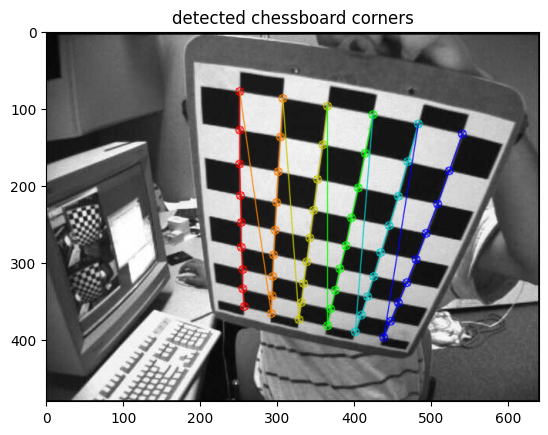

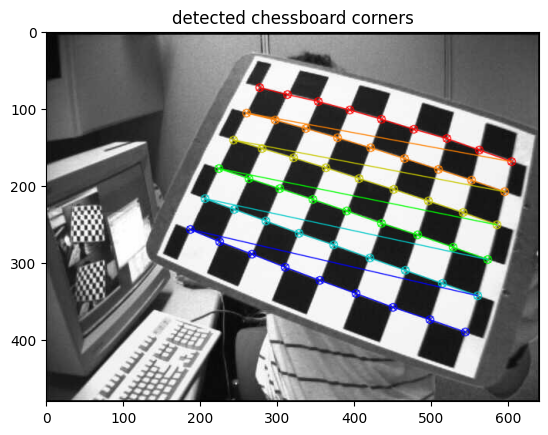

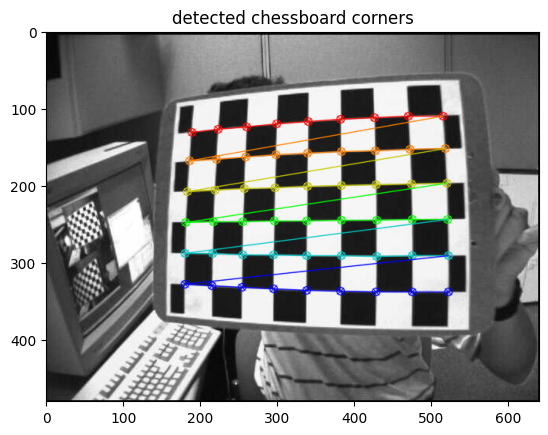

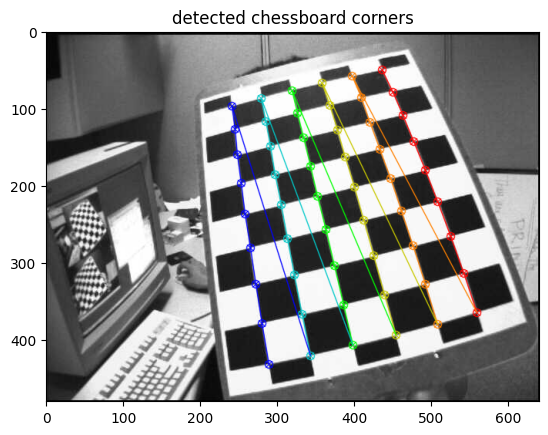

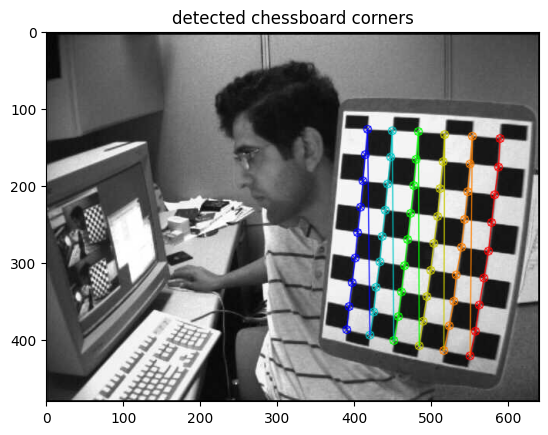

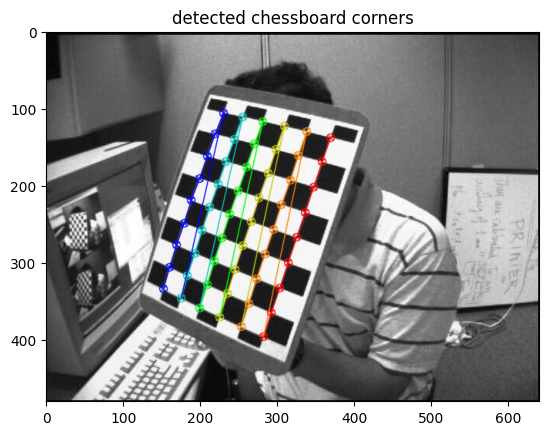

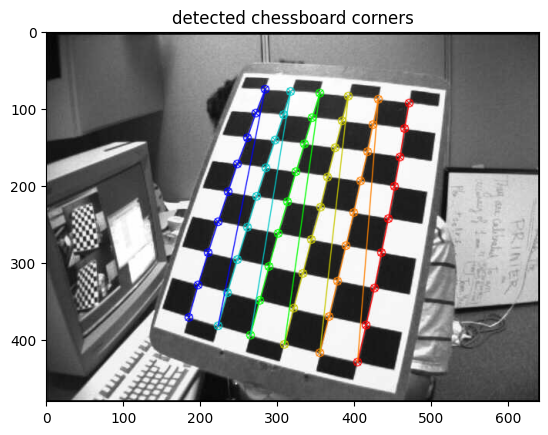

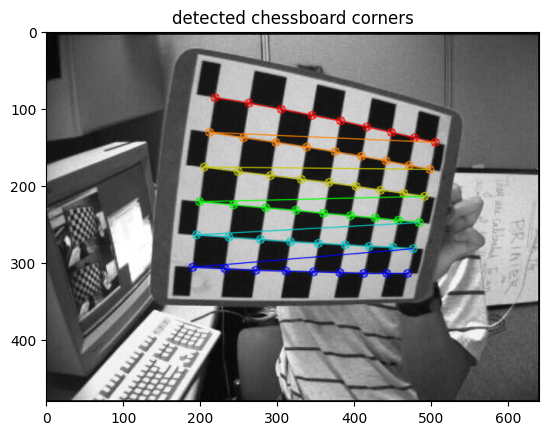

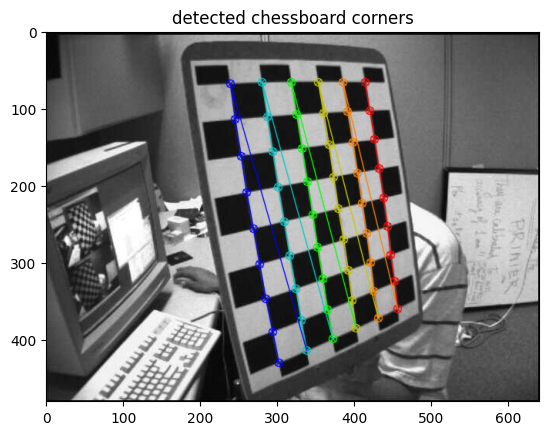

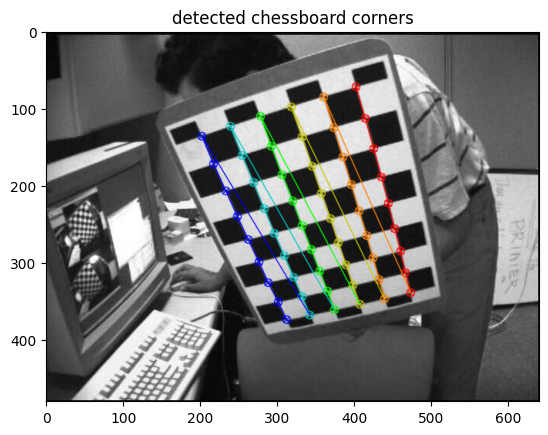

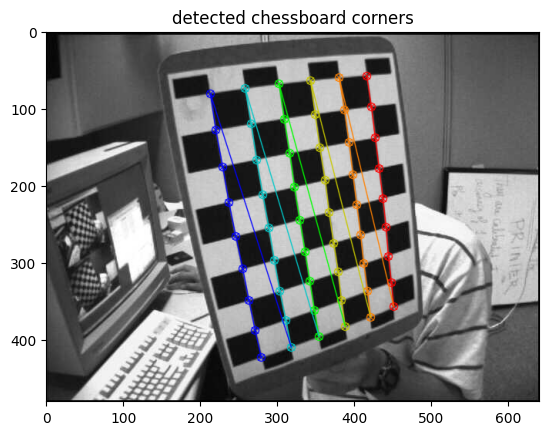

camera matrix:
[[532.42764942   0.         342.0315194 ]
 [  0.         532.64167846 235.38724941]
 [  0.           0.           1.        ]]
distortion coefficients:
[[-0.27453562 -0.01756824  0.00119981 -0.00034758  0.2358573 ]]
calibration error: 0.34467526721141023


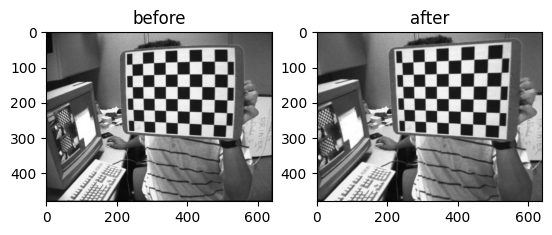

In [5]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

board = (9, 6)

image_urls = [
    "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/left01.jpg",
    "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/left02.jpg",
    "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/left03.jpg",
    "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/left04.jpg",
    "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/left05.jpg",
    "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/left06.jpg",
    "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/left07.jpg",
    "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/left08.jpg",
    "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/left09.jpg",
    "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/left11.jpg",
    "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/left13.jpg",
    "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/left14.jpg"
]

object_points = np.zeros((board[0] * board[1], 3), np.float32)
object_points[:, :2] = np.mgrid[0:board[0], 0:board[1]].T.reshape(-1, 2)

all_object_points = []
all_image_points = []

original = None
image_size = None

for url in image_urls:
    try:
        data = urllib.request.urlopen(url, timeout=15).read()
        img = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)

        if img is None:
            continue

        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        image_size = gray.shape[::-1]

        found, corners = cv2.findChessboardCorners(gray, board, None)

        if found:
            all_object_points.append(object_points.copy())
            all_image_points.append(corners)

            if original is None:
                original = img.copy()

            cv2.drawChessboardCorners(img, board, corners, found)
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            plt.title("detected chessboard corners")
            plt.show()

    except Exception as e:
        print("image could not be loaded:", e)

if len(all_object_points) >= 3:
    ret, camera_matrix, distortion, rvecs, tvecs = cv2.calibrateCamera(
        all_object_points, all_image_points, image_size, None, None
    )

    print("camera matrix:")
    print(camera_matrix)

    print("distortion coefficients:")
    print(distortion)

    print("calibration error:", ret)

    corrected = cv2.undistort(original, camera_matrix, distortion)

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    plt.title("before")

    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(corrected, cv2.COLOR_BGR2RGB))
    plt.title("after")

    plt.show()

else:
    print("not enough chessboard images detected")


fundamental matrix:
[[-1.37825070e-07  1.06855265e-05 -1.84177324e-03]
 [-1.88542101e-06 -3.38386001e-06 -5.24430795e-02]
 [-3.10852016e-04  5.23894884e-02  1.00000000e+00]]
number of good matches: 385
inlier matches: 295
Image 1:


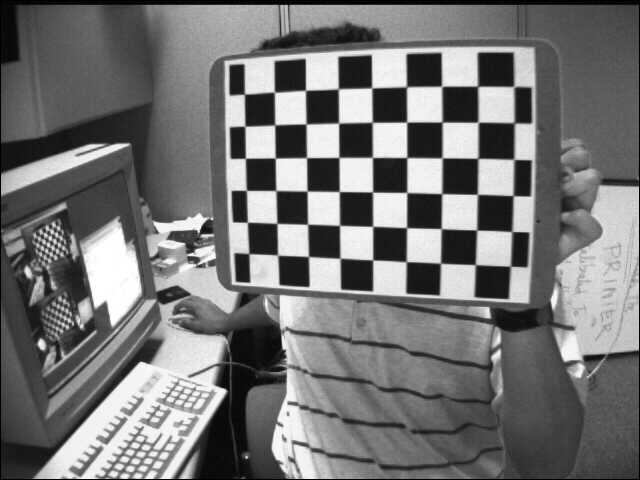

Image 2:


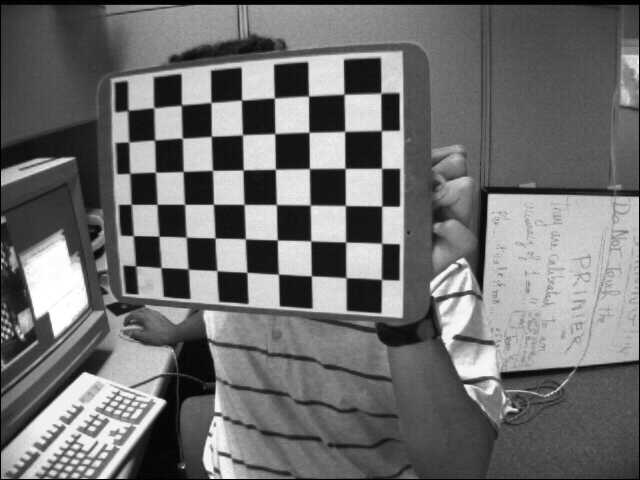

Matched Features:


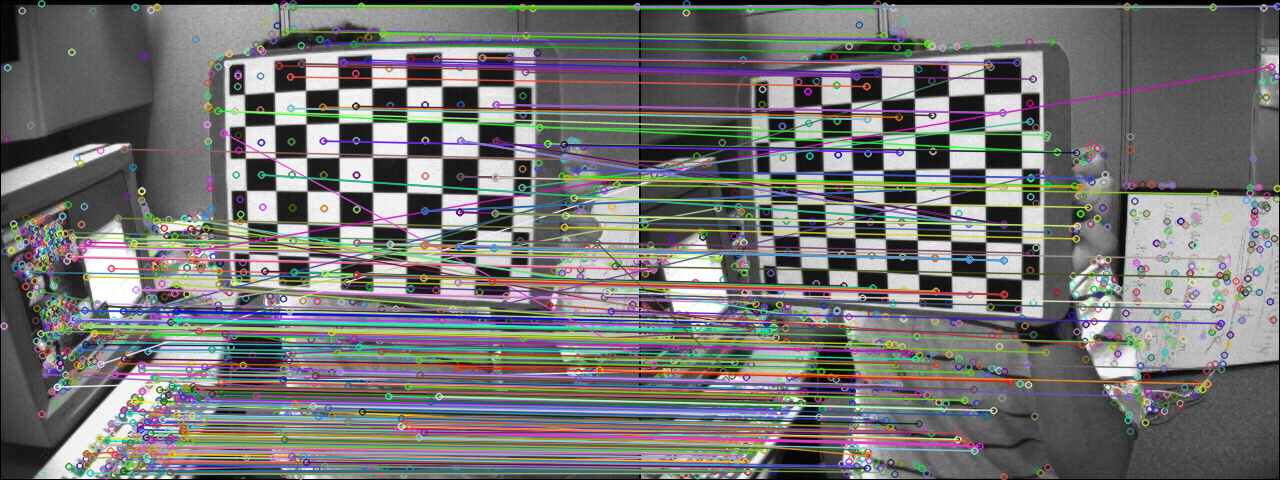

In [6]:
%pip install opencv-python numpy matplotlib

import cv2
import numpy as np
import urllib.request
from google.colab.patches import cv2_imshow

url1 = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/left01.jpg"
url2 = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/right01.jpg"

data1 = urllib.request.urlopen(url1).read()
data2 = urllib.request.urlopen(url2).read()

img1 = cv2.imdecode(np.frombuffer(data1, np.uint8), cv2.IMREAD_COLOR)
img2 = cv2.imdecode(np.frombuffer(data2, np.uint8), cv2.IMREAD_COLOR)

if img1 is None or img2 is None:
    print("images could not be loaded")
else:
    gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
    gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

    sift = cv2.SIFT_create()
    key1, des1 = sift.detectAndCompute(gray1, None)
    key2, des2 = sift.detectAndCompute(gray2, None)

    if des1 is not None and des2 is not None:
        matches = cv2.BFMatcher().knnMatch(des1, des2, k=2)
        good = [m for pair in matches if len(pair) == 2
                for m, n in [pair] if m.distance < 0.75 * n.distance]

        if len(good) >= 8:
            points1 = np.float32([key1[m.queryIdx].pt for m in good])
            points2 = np.float32([key2[m.trainIdx].pt for m in good])

            fundamental, mask = cv2.findFundamentalMat(
                points1, points2, cv2.FM_RANSAC
            )

            print("fundamental matrix:")
            print(fundamental)
            print("number of good matches:", len(good))

            if mask is not None:
                print("inlier matches:", int(mask.sum()))
        else:
            print("not enough good matches found")
    else:
        print("features could not be detected")

print("Image 1:")
cv2_imshow(img1)

print("Image 2:")
cv2_imshow(img2)

matched_img = cv2.drawMatches(
    img1, key1, img2, key2, good, None
)

print("Matched Features:")
cv2_imshow(matched_img)

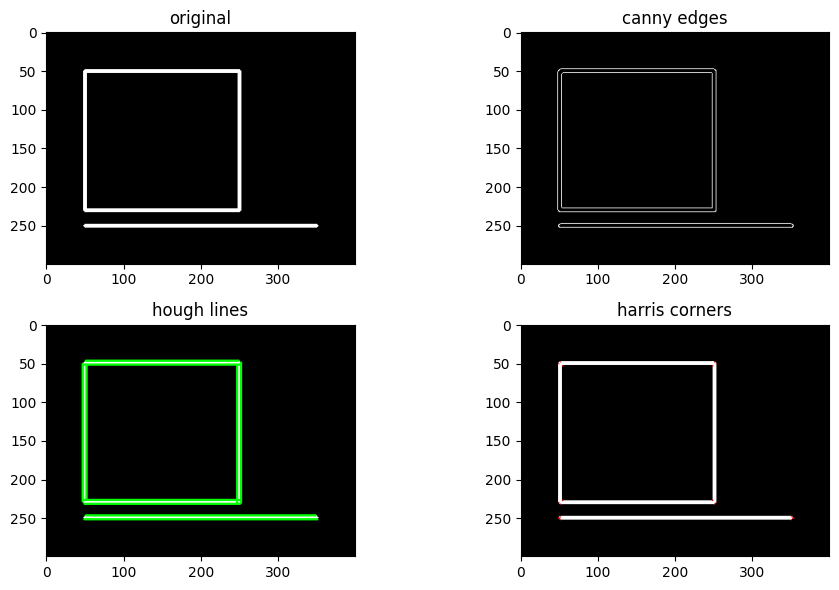

In [7]:
%pip install opencv-python numpy matplotlib

import cv2
import numpy as np
import matplotlib.pyplot as plt

img = np.zeros((300, 400, 3), dtype=np.uint8)
cv2.rectangle(img, (50, 50), (250, 230), (255, 255, 255), 3)
cv2.line(img, (50, 250), (350, 250), (255, 255, 255), 3)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

edges = cv2.Canny(gray, 50, 150)
line_image = img.copy()
lines = cv2.HoughLinesP(edges, 1, np.pi/180, 50, minLineLength=30, maxLineGap=10)

if lines is not None:
    for line in lines:
        # Securely flatten the line array to avoid unpacking scalar errors
        x1, y1, x2, y2 = line.ravel()
        cv2.line(line_image, (x1, y1), (x2, y2), (0, 255, 0), 2)

corners = cv2.cornerHarris(np.float32(gray), 2, 3, 0.04)
corner_image = img.copy()
corner_image[corners > 0.01 * corners.max()] = [0, 0, 255]

plt.figure(figsize=(10, 6))
plt.subplot(2, 2, 1); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.title("original")
plt.subplot(2, 2, 2); plt.imshow(edges, cmap="gray"); plt.title("canny edges")
plt.subplot(2, 2, 3); plt.imshow(cv2.cvtColor(line_image, cv2.COLOR_BGR2RGB)); plt.title("hough lines")
plt.subplot(2, 2, 4); plt.imshow(cv2.cvtColor(corner_image, cv2.COLOR_BGR2RGB)); plt.title("harris corners")
plt.tight_layout()
plt.show()

keypoints in image 1: 604
keypoints in image 2: 969
good matches: 80


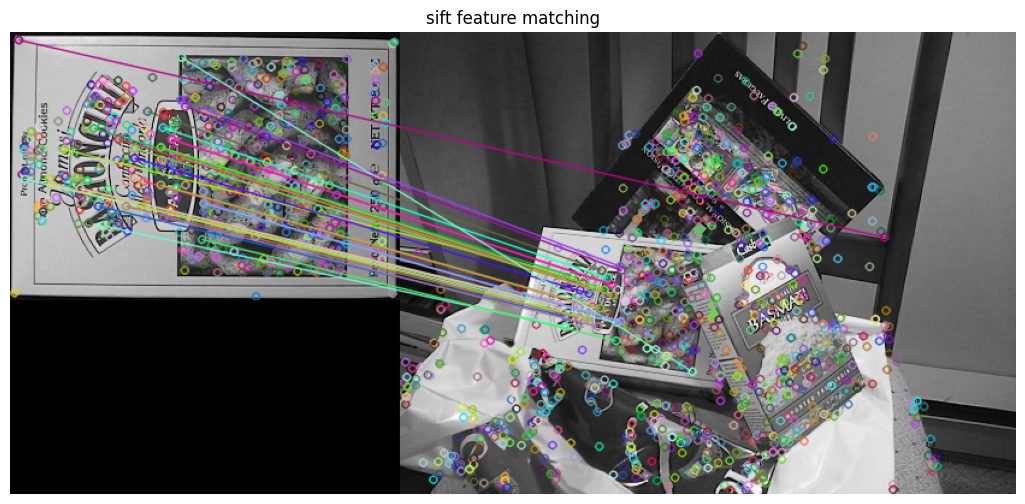

In [8]:

%pip install opencv-python numpy matplotlib

import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

url1 = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/box.png"
url2 = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/box_in_scene.png"

data1 = urllib.request.urlopen(url1).read()
data2 = urllib.request.urlopen(url2).read()

img1 = cv2.imdecode(np.frombuffer(data1, np.uint8), cv2.IMREAD_COLOR)
img2 = cv2.imdecode(np.frombuffer(data2, np.uint8), cv2.IMREAD_COLOR)

if img1 is None or img2 is None:
    print("images could not be loaded")
else:
    sift = cv2.SIFT_create()

    gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
    gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

    key1, des1 = sift.detectAndCompute(gray1, None)
    key2, des2 = sift.detectAndCompute(gray2, None)

    if des1 is not None and des2 is not None:
        matches = cv2.BFMatcher().knnMatch(des1, des2, k=2)

        good = [m for pair in matches if len(pair) == 2
                for m, n in [pair] if m.distance < 0.75 * n.distance]

        result = cv2.drawMatches(img1, key1, img2, key2, good[:30], None)

        print("keypoints in image 1:", len(key1))
        print("keypoints in image 2:", len(key2))
        print("good matches:", len(good))

        plt.figure(figsize=(14, 6))
        plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
        plt.title("sift feature matching")
        plt.axis("off")
        plt.show()
    else:
        print("features could not be detected")


In [9]:
%pip uninstall -y opencv-python opencv-contrib-python opencv-python-headless
%pip install opencv-python==4.11.0.86

Found existing installation: opencv-python 4.11.0.86
Uninstalling opencv-python-4.11.0.86:
  Successfully uninstalled opencv-python-4.11.0.86
  Using cached opencv_python-4.11.0.86-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (20 kB)
Using cached opencv_python-4.11.0.86-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (63.0 MB)


In [10]:
import cv2

print(cv2.__version__)
print(hasattr(cv2, "HOGDescriptor"))

4.11.0
True


In [11]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

img = np.zeros((300, 400, 3), dtype=np.uint8)

cv2.rectangle(img, (60, 50), (250, 250), (255, 255, 255), 3)
cv2.circle(img, (300, 100), 40, (255, 255, 255), 3)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

try:
    surf = cv2.xfeatures2d.SURF_create()
    keypoints, descriptors = surf.detectAndCompute(gray, None)

    surf_image = cv2.drawKeypoints(img, keypoints, None)

    print("surf keypoints:", len(keypoints))

    plt.imshow(cv2.cvtColor(surf_image, cv2.COLOR_BGR2RGB))
    plt.title("surf keypoints")
    plt.axis("off")
    plt.show()

except Exception:
    print("surf is not enabled in this opencv installation")

hog = cv2.HOGDescriptor((64, 128), (16, 16), (8, 8), (8, 8), 9)

small_image = cv2.resize(gray, (64, 128))

features = hog.compute(small_image)

print("hog descriptor size:", features.shape)


surf is not enabled in this opencv installation
hog descriptor size: (3780,)


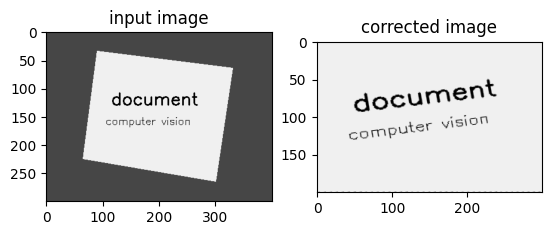

In [12]:

%pip install opencv-python numpy matplotlib

import cv2
import numpy as np
import matplotlib.pyplot as plt

img = np.zeros((300, 400, 3), dtype=np.uint8) + 70

cv2.fillConvexPoly(img, np.array([[90, 35], [330, 65], [300, 265], [65, 225]]), (240, 240, 240))
cv2.putText(img, "document", (115, 130), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 0), 2)
cv2.putText(img, "computer vision", (105, 165), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 1)

source = np.float32([[90, 35], [330, 65], [300, 265], [65, 225]])
destination = np.float32([[0, 0], [299, 0], [299, 199], [0, 199]])

matrix = cv2.getPerspectiveTransform(source, destination)
output = cv2.warpPerspective(img, matrix, (300, 200))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("input image")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("corrected image")

plt.show()
